<a href="https://colab.research.google.com/github/emf2229/Assignments/blob/main/ML_For_Climate_Assignment_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# To facilitate downloading data from Kaggle, we can install this python package
!pip install kagglehub

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("naiyakhalid/flood-prediction-dataset")

print("Path to dataset files:", path)

100%|██████████| 28.6M/28.6M [00:00<00:00, 175MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/naiyakhalid/flood-prediction-dataset/versions/2


In [3]:
import os
os.listdir(path)

['train.csv', 'test.csv', 'flood.csv', 'sample_submission.csv']

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 24
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

In [5]:
df = pd.read_csv(os.path.join(path, "flood.csv"))

print("Shape:", df.shape)
df.head()

Shape: (50000, 21)


,MonsoonIntensity,TopographyDrainage,RiverManagement,Deforestation,Urbanization,ClimateChange,DamsQuality,Siltation,AgriculturalPractices,Encroachments,...,DrainageSystems,CoastalVulnerability,Landslides,Watersheds,DeterioratingInfrastructure,PopulationScore,WetlandLoss,InadequatePlanning,PoliticalFactors,FloodProbability
0,3,8,6,6,4,4,6,2,3,2,...,10,7,4,2,3,4,3,2,6,0.450
1,8,4,5,7,7,9,1,5,5,4,...,9,2,6,2,1,1,9,1,3,0.475
2,3,10,4,1,7,5,4,7,4,9,...,7,4,4,8,6,1,8,3,6,0.515
3,4,4,2,7,3,4,1,4,6,4,...,4,2,6,6,8,8,6,6,10,0.520
4,3,7,5,2,5,8,5,2,7,5,...,7,6,5,3,3,4,4,3,4,0.475


In [6]:
print(df.describe())
print("\nMissing values:\n", df.isnull().sum())

       MonsoonIntensity  TopographyDrainage  RiverManagement  Deforestation  \
count      50000.000000        50000.000000      50000.00000   50000.000000   
mean           4.991480            4.984100          5.01594       5.008480   
std            2.236834            2.246488          2.23131       2.222743   
min            0.000000            0.000000          0.00000       0.000000   
25%            3.000000            3.000000          3.00000       3.000000   
50%            5.000000            5.000000          5.00000       5.000000   
75%            6.000000            6.000000          6.00000       6.000000   
max           16.000000           18.000000         16.00000      17.000000   

       Urbanization  ClimateChange  DamsQuality     Siltation  \
count  50000.000000   50000.000000  50000.00000  50000.000000   
mean       4.989060       4.988340      5.01536      4.988600   
std        2.243159       2.226761      2.24500      2.232642   
min        0.000000       0.

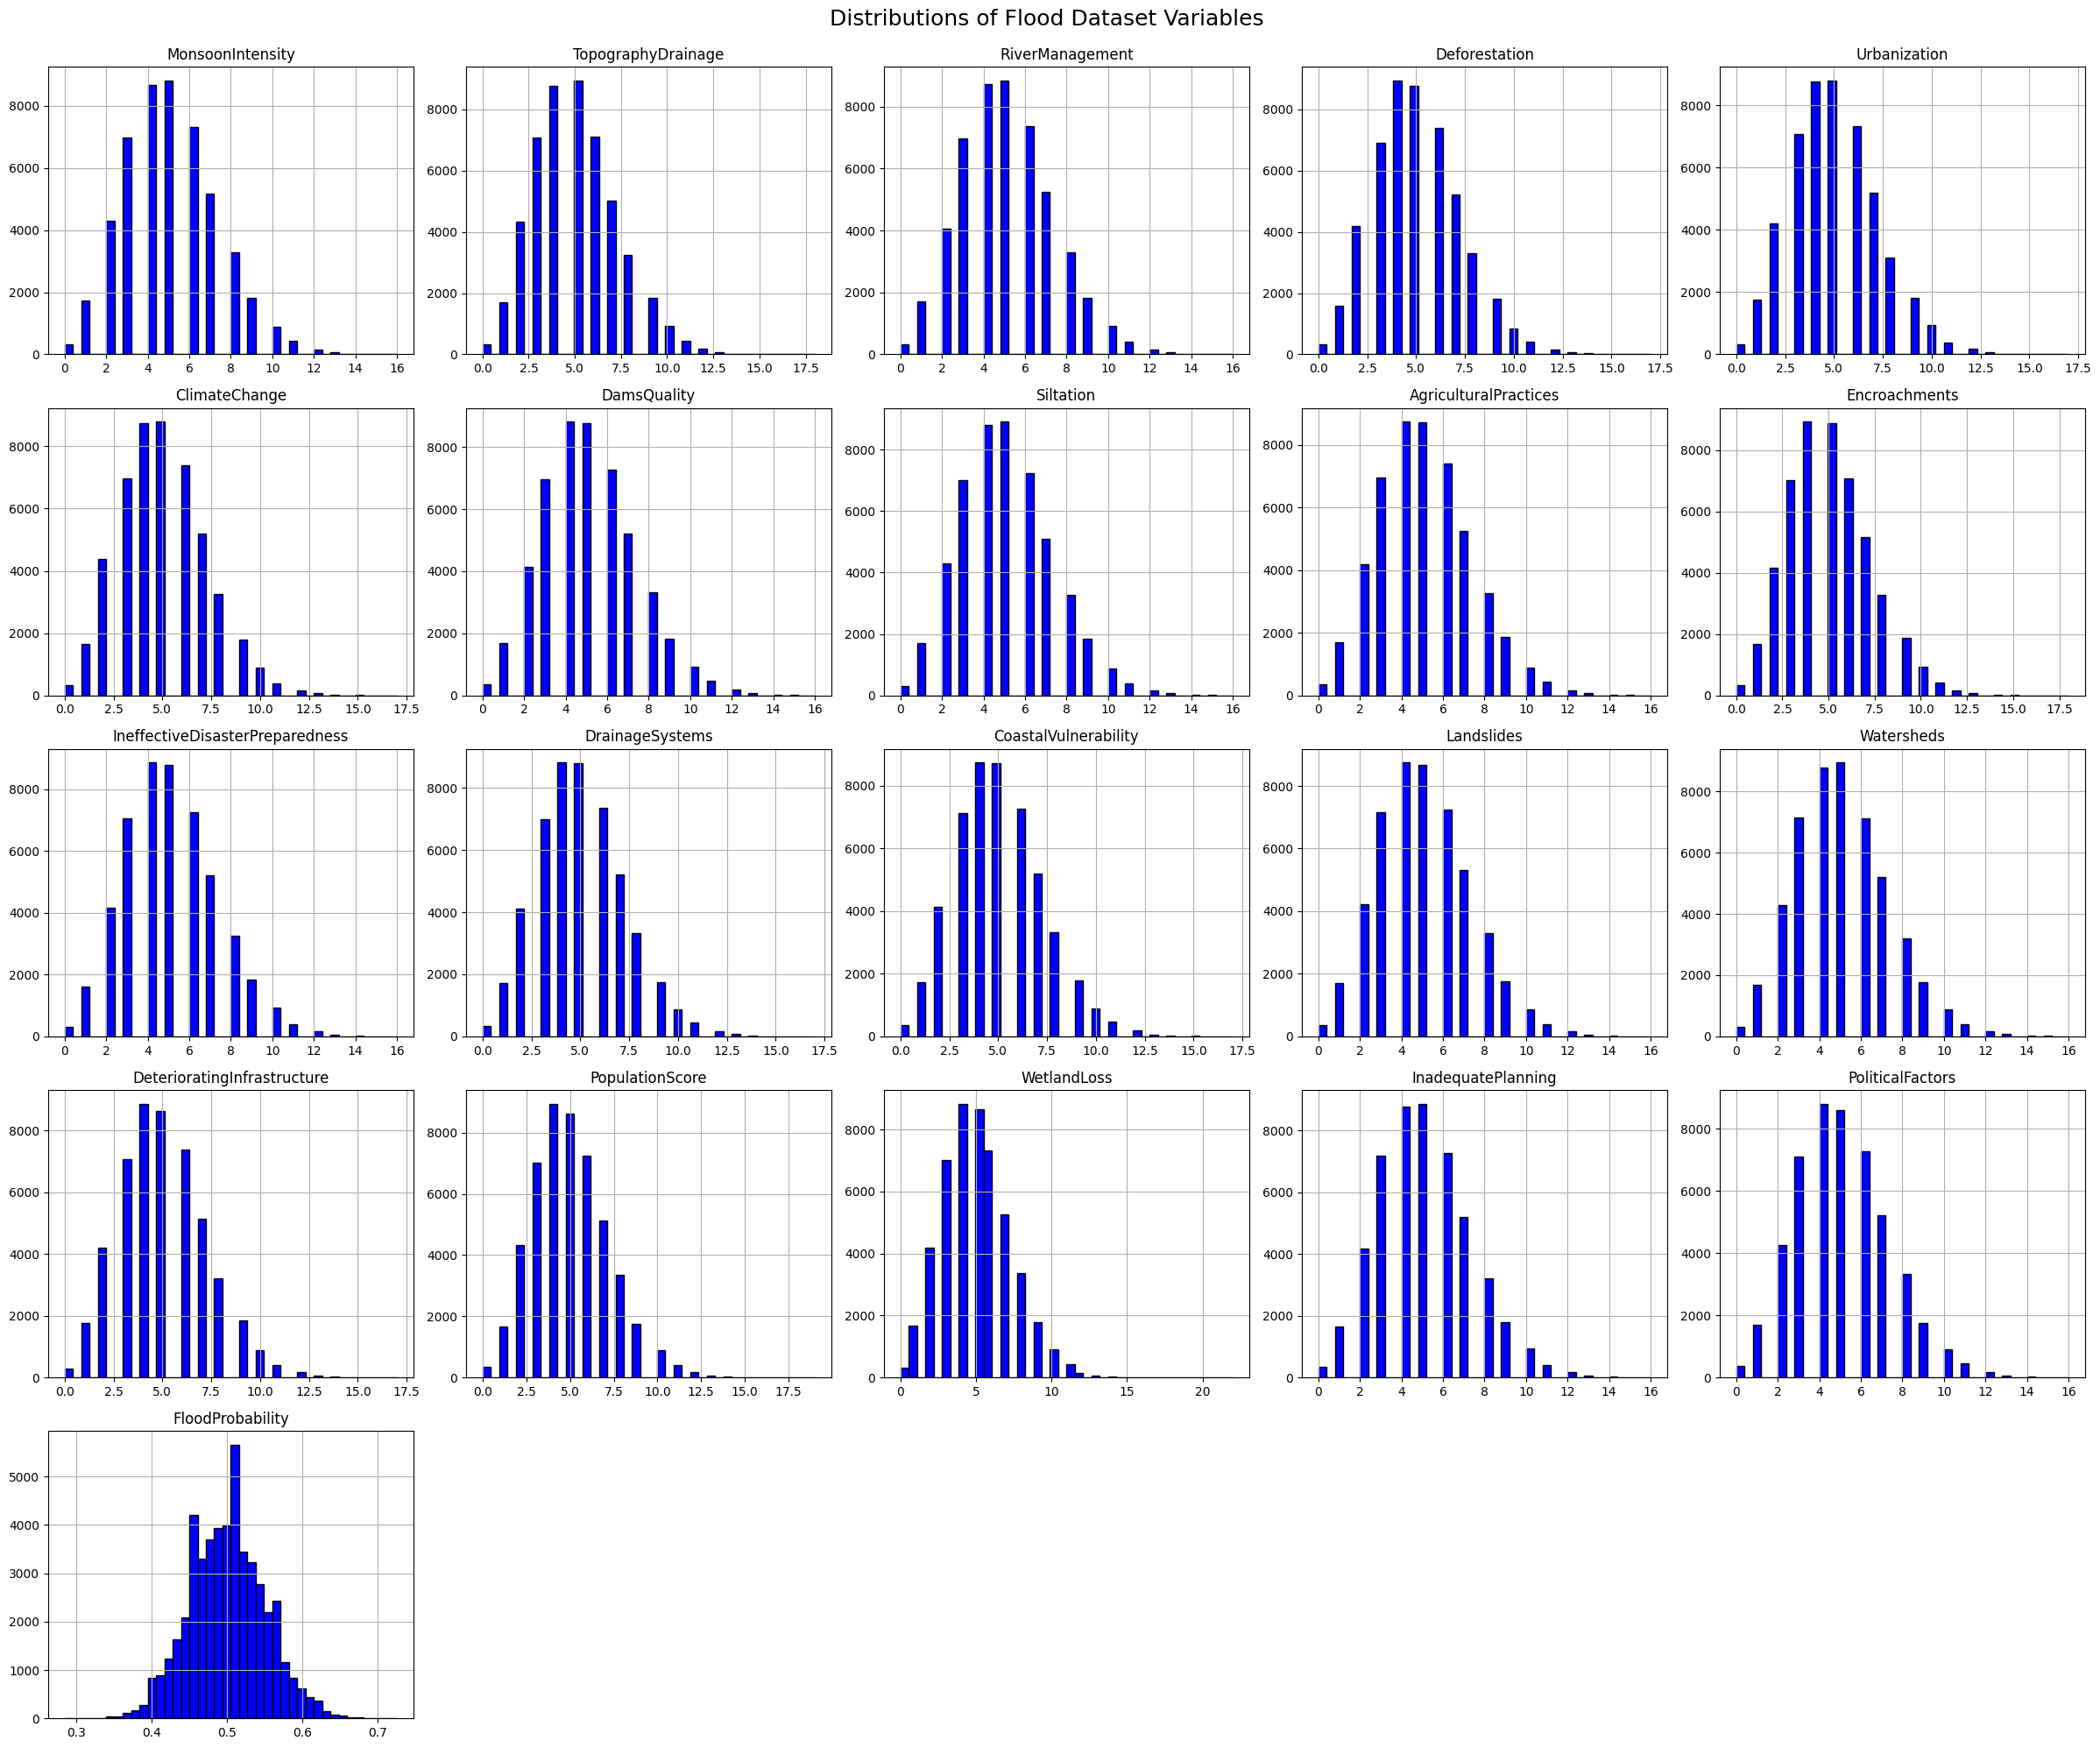

In [7]:
df.hist(bins=40, figsize=(24, 20), edgecolor="black", color="blue")
plt.suptitle("Distributions of Flood Dataset Variables", fontsize=18, y=0.995)
plt.tight_layout()
plt.show()

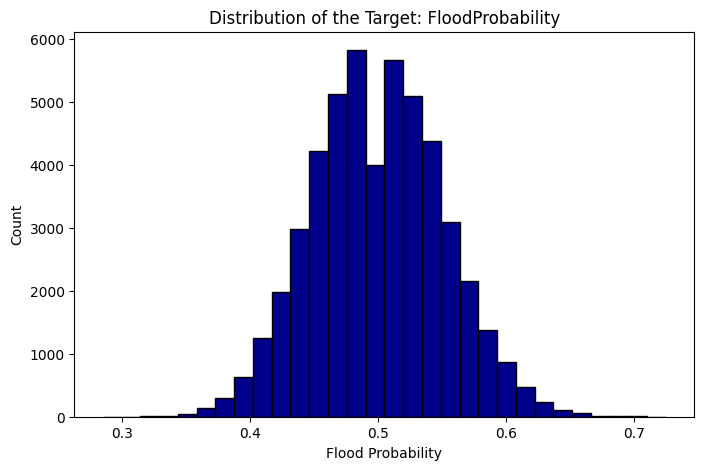

In [8]:
plt.figure(figsize=(8, 5))
plt.hist(df["FloodProbability"], bins=30, edgecolor="black", color="darkblue")
plt.xlabel("Flood Probability")
plt.ylabel("Count")
plt.title("Distribution of the Target: FloodProbability")
plt.show()

In [9]:
y = df["FloodProbability"].to_numpy()
X = df.drop(columns=["FloodProbability"]).to_numpy()

feature_names = df.drop(columns=["FloodProbability"]).columns.tolist()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Features:", feature_names)

X shape: (50000, 20)
y shape: (50000,)
Features: ['MonsoonIntensity', 'TopographyDrainage', 'RiverManagement', 'Deforestation', 'Urbanization', 'ClimateChange', 'DamsQuality', 'Siltation', 'AgriculturalPractices', 'Encroachments', 'IneffectiveDisasterPreparedness', 'DrainageSystems', 'CoastalVulnerability', 'Landslides', 'Watersheds', 'DeterioratingInfrastructure', 'PopulationScore', 'WetlandLoss', 'InadequatePlanning', 'PoliticalFactors']


In [10]:
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y.reshape(-1, 1))

print("X_scaled mean (first 5):", np.round(X_scaled.mean(axis=0)[:5], 6))
print("X_scaled std  (first 5):", np.round(X_scaled.std(axis=0)[:5], 6))
print("y_scaled mean: %.6f | std: %.6f" % (y_scaled.mean(), y_scaled.std()))
print("Original y -> mean: %.4f, std: %.4f" % (y.mean(), y.std()))

X_scaled mean (first 5): [-0.  0.  0.  0. -0.]
X_scaled std  (first 5): [1. 1. 1. 1. 1.]
y_scaled mean: -0.000000 | std: 1.000000
Original y -> mean: 0.4997, std: 0.0500


In [11]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X_scaled, y_scaled, test_size=0.20, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE
)

n_total = X_scaled.shape[0]
print("Train: %s (%.1f%%)" % (X_train.shape, 100 * len(X_train) / n_total))
print("Val:   %s (%.1f%%)" % (X_val.shape, 100 * len(X_val) / n_total))
print("Test:  %s (%.1f%%)" % (X_test.shape, 100 * len(X_test) / n_total))

Train: (40000, 20) (80.0%)
Val:   (5000, 20) (10.0%)
Test:  (5000, 20) (10.0%)


In [12]:
n_features = X_train.shape[1]

model = tf.keras.Sequential(
    [
        tf.keras.layers.Input(shape=(n_features,), name="input_layer"),
        tf.keras.layers.Dense(100, activation="relu", name="hidden_1"),
        tf.keras.layers.Dense(100, activation="relu", name="hidden_2"),
        tf.keras.layers.Dense(100, activation="relu", name="hidden_3"),
        tf.keras.layers.Dense(1, name="output"),
    ],
    name="flood_probability_regressor",
)

In [13]:
model.summary()

total_params = int(sum(np.prod(w.shape) for w in model.trainable_weights))
print("\n  hidden_1:  20 x 100 + 100 =  2,100")
print("  hidden_2: 100 x 100 + 100 = 10,100")
print("  hidden_3: 100 x 100 + 100 = 10,100")
print("  output:   100 x   1 +   1 =    101")
print("  " + "-" * 34)
print("  TOTAL trainable parameters: {:,}".format(total_params))

Model: "flood_probability_regressor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 100)            │         2,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_3 (Dense)                │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,401 (87.50 KB)

 Trainable params: 22,401 (87.50 KB)

 Non-trainable params: 0 (0.00 B)


  hidden_1:  20 x 100 + 100 =  2,100
  hidden_2: 100 x 100 + 100 = 10,100
  hidden_3: 100 x 100 + 100 = 10,100
  output:   100 x   1 +   1 =    101
  ----------------------------------
  TOTAL trainable parameters: 22,401


In [14]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=[tf.keras.metrics.RootMeanSquaredError(name="rmse")],
)

In [15]:
history = model.fit(
    X_train,
    y_train,
    epochs=30,
    validation_data=(X_val, y_val),
    batch_size=40,
    verbose=1,
)

Epoch 1/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0267 - rmse: 0.1634 - val_loss: 0.0027 - val_rmse: 0.0517
Epoch 2/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0020 - rmse: 0.0451 - val_loss: 0.0012 - val_rmse: 0.0345
Epoch 3/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 9.9730e-04 - rmse: 0.0316 - val_loss: 6.2651e-04 - val_rmse: 0.0250
Epoch 4/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 5.5429e-04 - rmse: 0.0235 - val_loss: 3.4017e-04 - val_rmse: 0.0184
Epoch 5/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 3.4149e-04 - rmse: 0.0185 - val_loss: 2.5346e-04 - val_rmse: 0.0159
Epoch 6/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 2.6778e-04 - rmse: 0.0164 - val_loss: 2.0529e-04 - val_rmse: 0.0143
Epoch 7/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 1.6275e-04 - rmse: 0.0128 - val_loss: 3.0018e-04 - val_rmse: 0.0173
Epoch 8/30
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 1.3328e-04 - rmse: 0.0115 - val_loss: 1.0796

In [ ]:
epochs = range(1, len(history.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(28, 10))

axes[0].plot(epochs, history.history["loss"], "o-", label="Training loss")
axes[0].plot(epochs, history.history["val_loss"], "s-", label="Validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Mean Squared Error (scaled units)")
axes[0].set_title("Training vs. Validation Loss")
axes[0].set_yscale("log")
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history.history["rmse"], "o-", label="Training RMSE")
axes[1].plot(epochs, history.history["val_rmse"], "s-", label="Validation RMSE")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Root Mean Squared Error (scaled units)")
axes[1].set_title("Training vs. Validation RMSE")
axes[1].set_yscale("log")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Final training loss:   %.6f" % history.history["loss"][-1])
print("Final validation loss: %.6f" % history.history["val_loss"][-1])

In [16]:
model.save("flood_model.keras")

In [17]:
test_loss, test_rmse = model.evaluate(X_test, y_test, verbose=0)
print("Test MSE loss (scaled units): %.6f" % test_loss)
print("Test RMSE     (scaled units): %.6f" % test_rmse)

Test MSE loss (scaled units): 0.000018
Test RMSE     (scaled units): 0.004236


In [18]:
y_pred_scaled = model.predict(X_test, verbose=0)

print("Predictions shape:", y_pred_scaled.shape)
print("First five scaled predictions:", np.round(y_pred_scaled[:5].ravel(), 4))
print("First five scaled true values:", np.round(y_test[:5].ravel(), 4))

Predictions shape: (5000, 1)
First five scaled predictions: [ 4.9800e-01  2.5000e-03  3.1877e+00  4.0490e-01 -3.9080e-01]
First five scaled true values: [ 0.5064  0.0068  3.2046  0.4065 -0.3929]


In [19]:
y_test_unscaled = scaler_y.inverse_transform(y_test).ravel()
y_pred_unscaled = scaler_y.inverse_transform(y_pred_scaled).ravel()

print("First five true probabilities:      ", np.round(y_test_unscaled[:5], 4))
print("First five predicted probabilities: ", np.round(y_pred_unscaled[:5], 4))

rmse_unscaled = np.sqrt(np.mean((y_test_unscaled - y_pred_unscaled) ** 2))
mae_unscaled = np.mean(np.abs(y_test_unscaled - y_pred_unscaled))
ss_res = np.sum((y_test_unscaled - y_pred_unscaled) ** 2)
ss_tot = np.sum((y_test_unscaled - y_test_unscaled.mean()) ** 2)
r2 = 1 - ss_res / ss_tot

print("\nTest metrics in original flood-probability units:")
print("  RMSE: %.6f" % rmse_unscaled)
print("  MAE:  %.6f" % mae_unscaled)
print("  R^2:  %.6f" % r2)

First five true probabilities:       [0.525 0.5   0.66  0.52  0.48 ]
First five predicted probabilities:  [0.5246 0.4998 0.6592 0.5199 0.4801]

Test metrics in original flood-probability units:
  RMSE: 0.000212
  MAE:  0.000156
  R^2:  0.999982


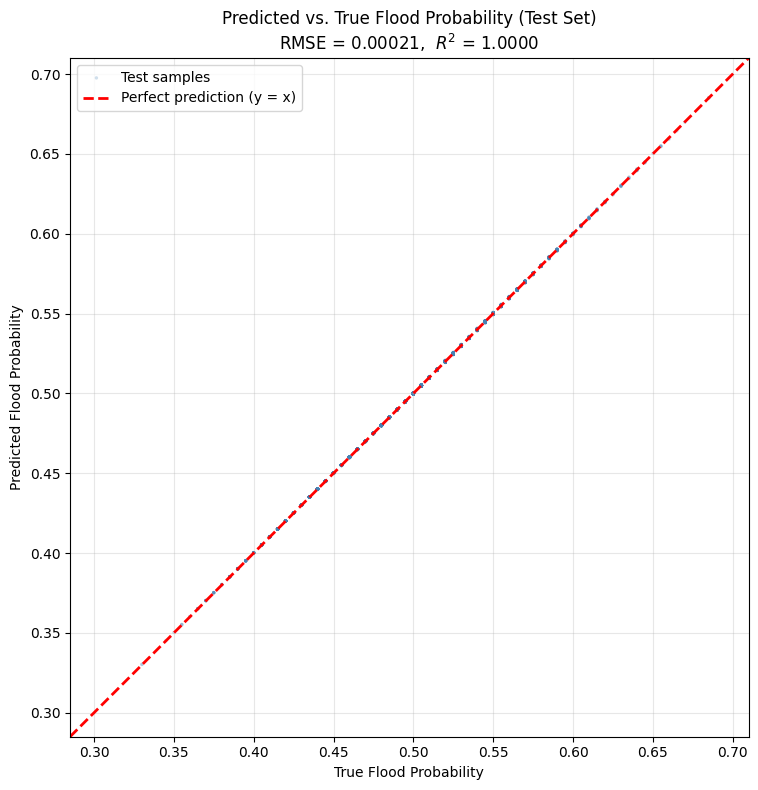

In [20]:
lo = min(y_test_unscaled.min(), y_pred_unscaled.min())
hi = max(y_test_unscaled.max(), y_pred_unscaled.max())

plt.figure(figsize=(8, 8))
plt.scatter(y_test_unscaled, y_pred_unscaled, s=6, alpha=0.25,
            color="steelblue", edgecolors="none", label="Test samples")
plt.plot([lo, hi], [lo, hi], "r--", linewidth=2, label="Perfect prediction (y = x)")
plt.xlabel("True Flood Probability")
plt.ylabel("Predicted Flood Probability")
plt.title("Predicted vs. True Flood Probability (Test Set)\n"
          "RMSE = %.5f,  $R^2$ = %.4f" % (rmse_unscaled, r2))
plt.legend()
plt.grid(alpha=0.3)
plt.xlim(lo, hi)
plt.ylim(lo, hi)
plt.gca().set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.show()